In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_2024.csv")

df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df["quarter"] = df["order_date"].dt.quarter
df["profit_margin"] = df["profit"] / df["revenue"] * 100

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

df.head()

Shape: (1000, 18)
Missing values: 0


,order_id,order_date,region,category,product,quantity,unit_price,discount,revenue,profit,customer_age,customer_gender,payment_method,delivery_days,rating,month,quarter,profit_margin
0,ORD1001,2024-01-01,West,Clothing,Jeans,4,1730.0,0.00,6920.0,2636.14,45,Male,Debit Card,3,3.0,1,1,38.094509
1,ORD1002,2024-01-01,South,Sports,Dumbbell Set,1,2360.0,0.00,2360.0,690.43,39,Female,Credit Card,2,4.0,1,1,29.255508
2,ORD1003,2024-01-02,East,Clothing,T-Shirt,2,680.0,0.00,1360.0,456.07,31,Male,Credit Card,5,4.0,1,1,33.534559
3,ORD1004,2024-01-02,East,Clothing,Sneakers,3,2760.0,0.30,5796.0,887.30,24,Female,Credit Card,4,5.0,1,1,15.308834
4,ORD1005,2024-01-03,South,Clothing,Sneakers,2,2810.0,0.05,5339.0,1531.46,54,Female,UPI,2,3.0,1,1,28.684398


/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/789918990.py:16: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


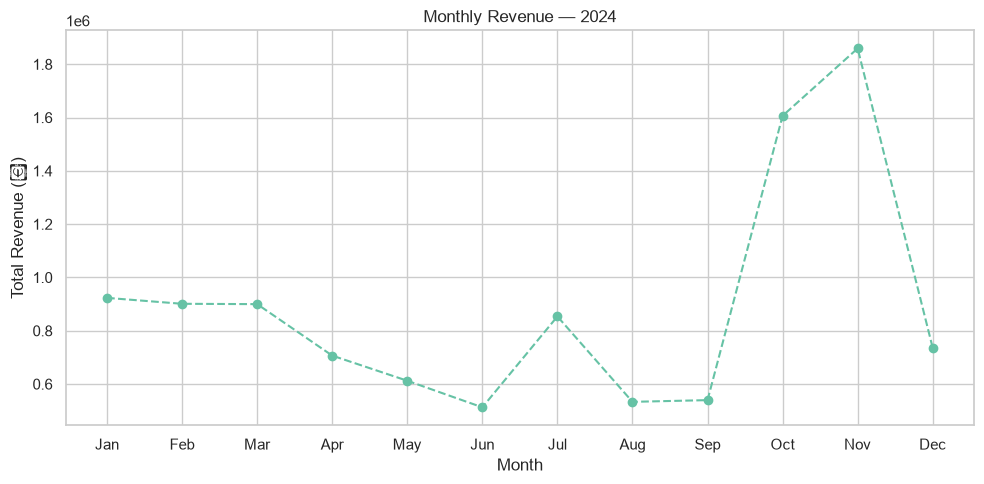

In [81]:
# 1

monthly_revenue = df.groupby("month")["revenue"].sum()

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values,
         marker="o", linestyle="--")
plt.xticks(range(1, 13), months)
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.title("Monthly Revenue — 2024")
plt.grid(True)
plt.tight_layout()
plt.show()

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/2472370614.py:16: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()


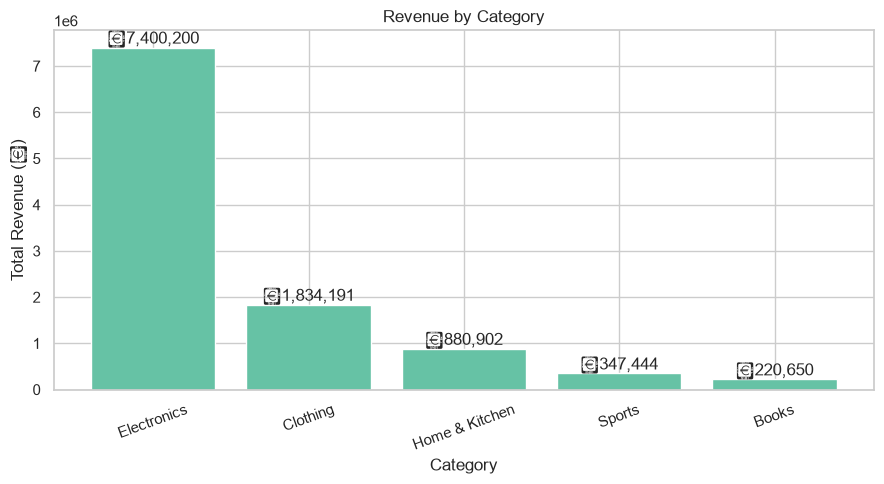

In [82]:
# 2

category_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
bars = plt.bar(category_revenue.index, category_revenue.values)

for bar, value in zip(bars, category_revenue.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"₹{value:,.0f}", ha="center", va="bottom")

plt.xlabel("Category")
plt.ylabel("Total Revenue (₹)")
plt.title("Revenue by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/3225563889.py:10: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()


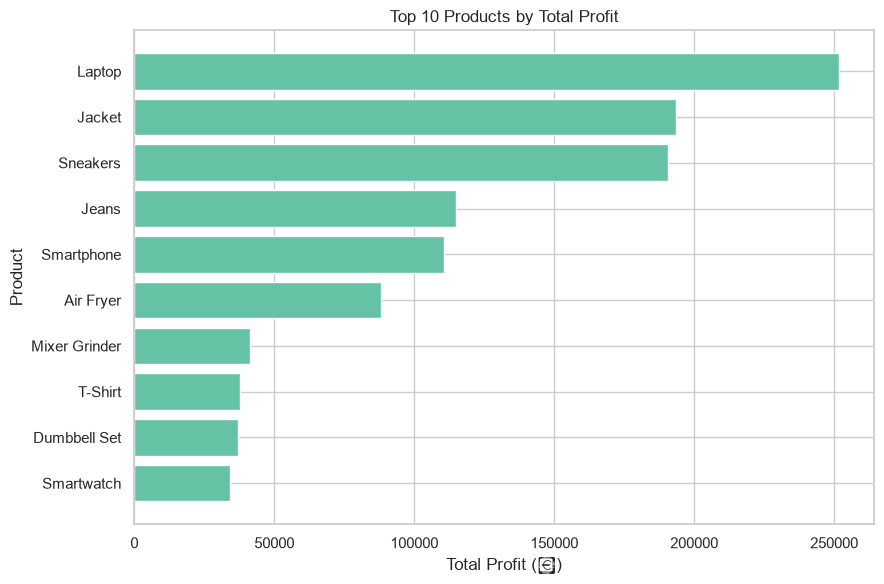

In [83]:
# 3

top_products = df.groupby("product")["profit"].sum().nlargest(10).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(top_products.index, top_products.values)
plt.xlabel("Total Profit (₹)")
plt.ylabel("Product")
plt.title("Top 10 Products by Total Profit")
plt.tight_layout()
plt.show()

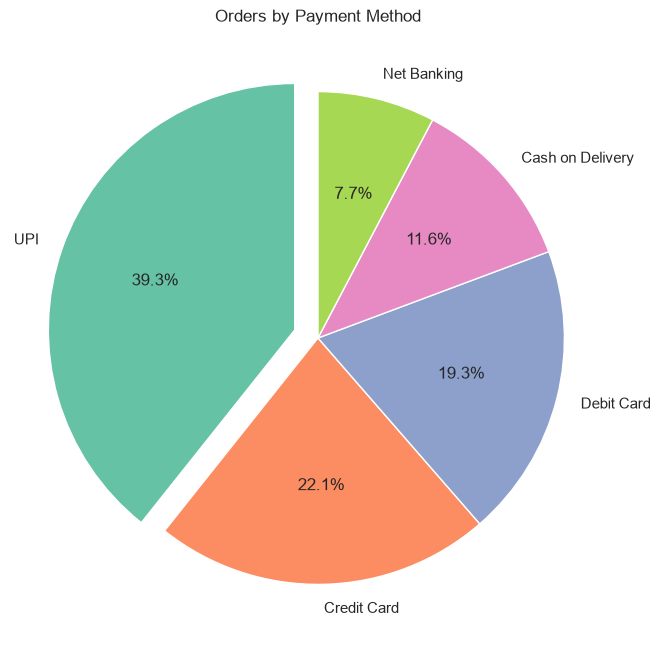

In [84]:
# 4

payment_counts = df["payment_method"].value_counts()

largest_index = payment_counts.argmax()
explode = [0.1 if i == largest_index else 0 for i in range(len(payment_counts))]

plt.figure(figsize=(8, 8))
plt.pie(payment_counts.values,
        labels=payment_counts.index,
        autopct="%.1f%%",
        explode=explode,
        startangle=90)
plt.title("Orders by Payment Method")
plt.show()

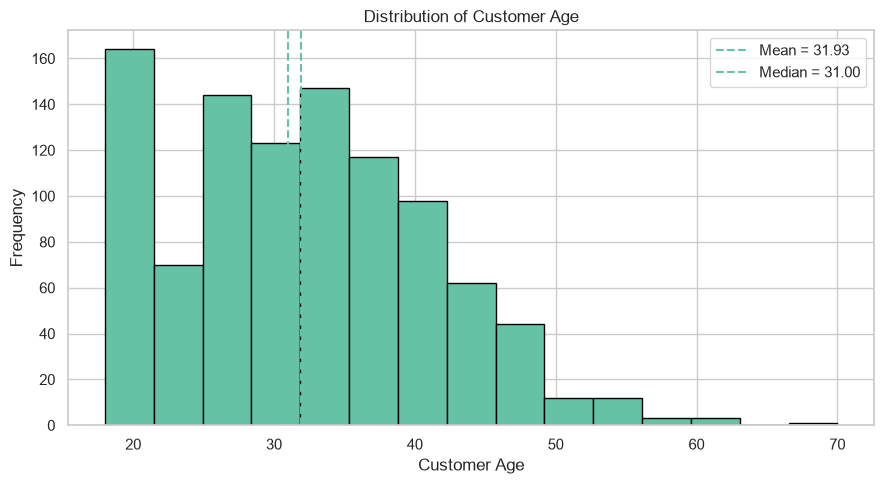

In [85]:
# 5

mean_age = df["customer_age"].mean()
median_age = df["customer_age"].median()

plt.figure(figsize=(9, 5))
plt.hist(df["customer_age"], bins=15, edgecolor="black")
plt.axvline(mean_age, linestyle="--", label=f"Mean = {mean_age:.2f}")
plt.axvline(median_age, linestyle="--", label=f"Median = {median_age:.2f}")
plt.xlabel("Customer Age")
plt.ylabel("Frequency")
plt.title("Distribution of Customer Age")
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/1901991154.py:14: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


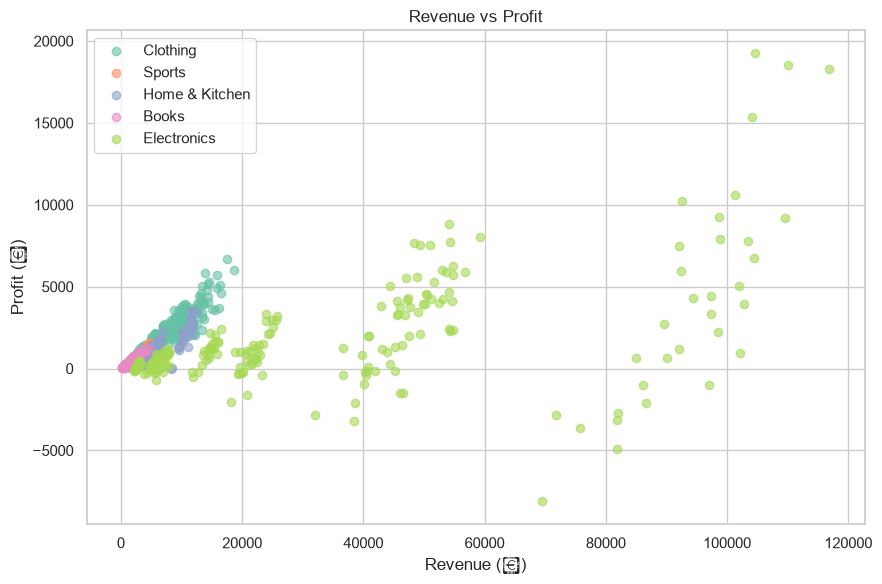

In [86]:
# 6

plt.figure(figsize=(9, 6))

for category in df["category"].unique():
    data = df[df["category"] == category]
    plt.scatter(data["revenue"], data["profit"],
                alpha=0.6, label=category)

plt.xlabel("Revenue (₹)")
plt.ylabel("Profit (₹)")
plt.title("Revenue vs Profit")
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/3687256448.py:27: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


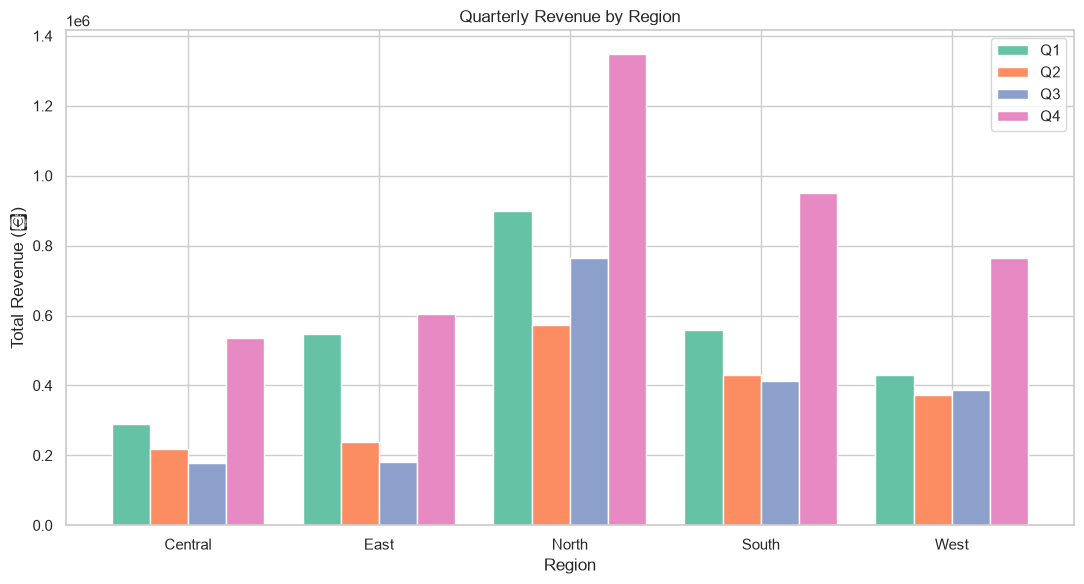

In [87]:
# 7

quarter_region = df.pivot_table(
    values="revenue",
    index="region",
    columns="quarter",
    aggfunc="sum"
)

regions = quarter_region.index
x = np.arange(len(regions))
width = 0.2

plt.figure(figsize=(11, 6))

for i, quarter in enumerate([1, 2, 3, 4]):
    plt.bar(x + (i - 1.5) * width,
            quarter_region[quarter],
            width,
            label=f"Q{quarter}")

plt.xticks(x, regions)
plt.xlabel("Region")
plt.ylabel("Total Revenue (₹)")
plt.title("Quarterly Revenue by Region")
plt.legend()
plt.tight_layout()
plt.show()

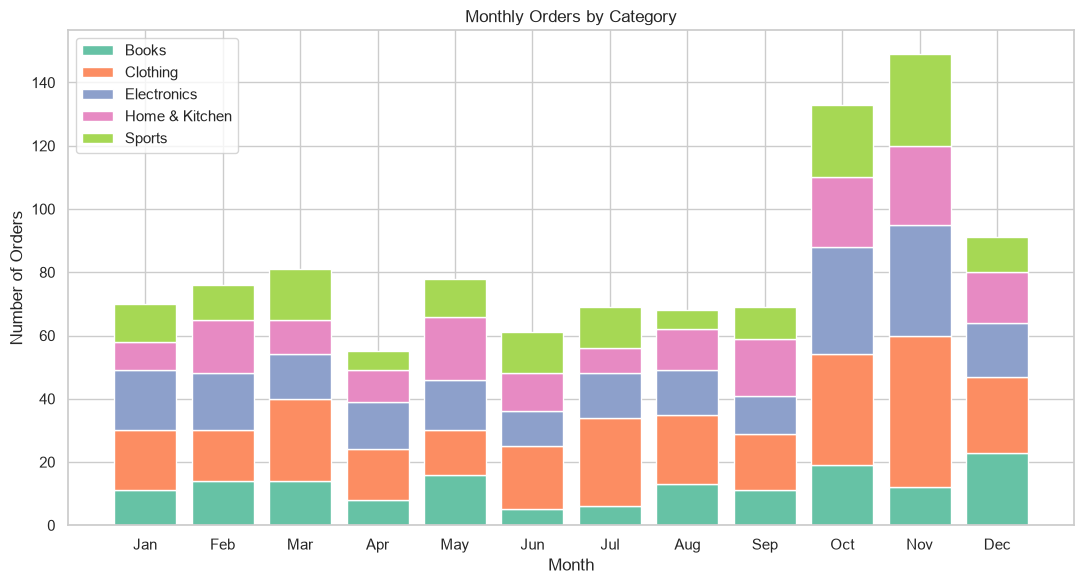

In [88]:
# 8

monthly_category = pd.crosstab(df["month"], df["category"])

months = range(1, 13)
bottom = np.zeros(12)

plt.figure(figsize=(11, 6))

for category in monthly_category.columns:
    values = monthly_category.reindex(months, fill_value=0)[category].values
    plt.bar(months, values, bottom=bottom, label=category)
    bottom += values

plt.xticks(months, ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.title("Monthly Orders by Category")
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/395111627.py:30: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8032/395111627.py:31: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig("matplotlib_grid.png", dpi=300, bbox_inches="tight")
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


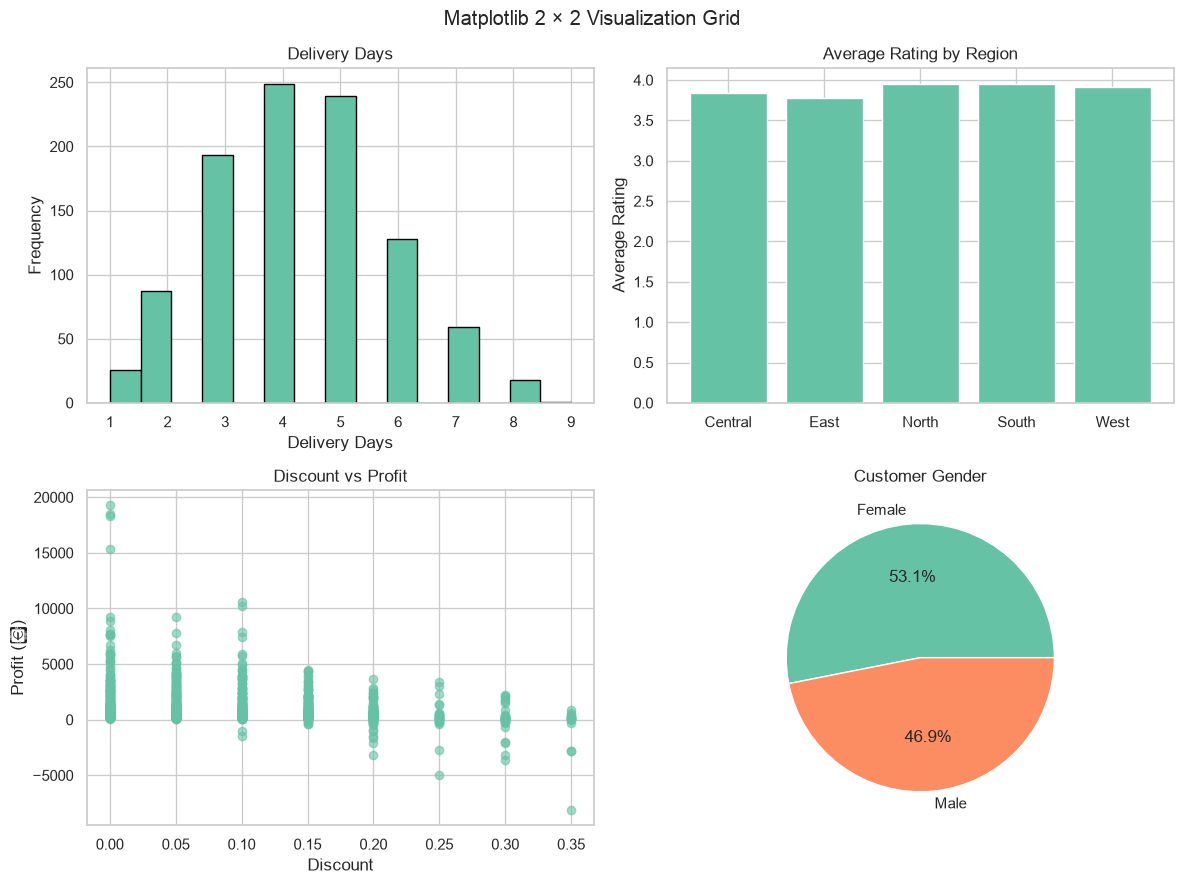

In [89]:
# 10

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].hist(df["delivery_days"], bins=15, edgecolor="black")
axes[0, 0].set_title("Delivery Days")
axes[0, 0].set_xlabel("Delivery Days")
axes[0, 0].set_ylabel("Frequency")


avg_rating_region = df.groupby("region")["rating"].mean()
axes[0, 1].bar(avg_rating_region.index, avg_rating_region.values)
axes[0, 1].set_title("Average Rating by Region")
axes[0, 1].set_ylabel("Average Rating")


axes[1, 0].scatter(df["discount"], df["profit"], alpha=0.6)
axes[1, 0].set_title("Discount vs Profit")
axes[1, 0].set_xlabel("Discount")
axes[1, 0].set_ylabel("Profit (₹)")


gender_counts = df["customer_gender"].value_counts()
axes[1, 1].pie(gender_counts.values,
               labels=gender_counts.index,
               autopct="%.1f%%")
axes[1, 1].set_title("Customer Gender")

fig.suptitle("Matplotlib 2 × 2 Visualization Grid")
plt.tight_layout()
plt.savefig("matplotlib_grid.png", dpi=300, bbox_inches="tight")
plt.show()